In [1]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("GE_OE_Cleaned_Data.csv")
print(df)

             Timestamp 3) What is your gender?  \
0   8/19/2026 10:57:56                    Male   
1    8/30/2026 7:55:20                    Male   
2    8/30/2026 9:28:03                    Male   
3   8/30/2026 10:11:59                    Male   
4   8/30/2026 10:32:12                    Male   
..                 ...                     ...   
87   9/8/2026 21:23:20                    Male   
88   9/8/2026 22:21:36                    Male   
89   9/8/2026 23:52:38                    Male   
90   9/9/2026 12:02:56                    Male   
91   9/9/2026 12:19:46                  Female   

   4) Which course/program are you studying?  \
0                                       B.SC   
1                                       B.SC   
2                                       B.SC   
3                                       B.SC   
4                                       B.SC   
..                                       ...   
87                                       B.A   
88             

In [2]:
# Display dataset information
print("Dataset Shape:", df.shape)

Dataset Shape: (92, 25)


In [3]:
# Select the target column
target_col = " 19) Overall, how satisfied are you with the  GE/OE   subjects offered by your college?   "

# Check satisfaction responses
print(df[target_col].value_counts(dropna=False))

 19) Overall, how satisfied are you with the  GE/OE   subjects offered by your college?   
Neutral              37
Satisfied            23
Very Satisfied       15
Dissatisfied         10
Very Dissatisfied     6
Not Answered          1
Name: count, dtype: int64


In [4]:
# Remove rows where overall satisfaction is not answered
df_ml = df[df[target_col] != "Not Answered"].copy()

# Check the new dataset size
print("Dataset Shape:", df_ml.shape)

# Check target values
print(df_ml[target_col].value_counts())

Dataset Shape: (91, 25)
 19) Overall, how satisfied are you with the  GE/OE   subjects offered by your college?   
Neutral              37
Satisfied            23
Very Satisfied       15
Dissatisfied         10
Very Dissatisfied     6
Name: count, dtype: int64


In [5]:
# Select input features
feature_cols = [
    '7) Are you aware that your college offers  GE/OE  Subject beyond the core curriculum',
    '8) Do you understand the purpose and objective behind offering these  GE/OE   subject ',
    ' 10) In your opinion,  GE/OE   subjects are:  ',
    '11)  Rate the following on a 5-point scale (1 = Strongly Disagree, 5 = Strongly Agree) [1) GE/OE subjects improve my communication skills]',
    '11)  Rate the following on a 5-point scale (1 = Strongly Disagree, 5 = Strongly Agree) [2) GE/OE subjects improve my technical/practical skills]',
    '11)  Rate the following on a 5-point scale (1 = Strongly Disagree, 5 = Strongly Agree) [3) GE/OE subjects contribute to my overall personality development]',
    '11)  Rate the following on a 5-point scale (1 = Strongly Disagree, 5 = Strongly Agree) [4) GE/OE subjects are relevant to my career goals]',
    '11)  Rate the following on a 5-point scale (1 = Strongly Disagree, 5 = Strongly Agree) [6) GE/OE subjects complement my core curriculum well]',
    '12)  Do  GE/OE  subjects increase your academic workload?  ',
    ' 18) How would you rate the teaching methodology used for  GE/OE   subjects?  '
]

X = df_ml[feature_cols]
y = df_ml[target_col]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (91, 10)
Target Shape: (91,)


In [6]:
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder

# Encode input features
encoder = OrdinalEncoder()
X_encoded = pd.DataFrame(
    encoder.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Encode target values
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Encoded Input Shape:", X_encoded.shape)
print("Encoded Target Shape:", y_encoded.shape)
print("\nTarget Classes:", label_encoder.classes_)

Encoded Input Shape: (91, 10)
Encoded Target Shape: (91,)

Target Classes: ['Dissatisfied' 'Neutral' 'Satisfied' 'Very Dissatisfied' 'Very Satisfied']


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (72, 10)
Testing data: (19, 10)


In [8]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=4,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

print("Model training completed!")
print("Predictions:", label_encoder.inverse_transform(y_pred))

Model training completed!
Predictions: ['Very Satisfied' 'Neutral' 'Neutral' 'Very Dissatisfied' 'Satisfied'
 'Satisfied' 'Neutral' 'Satisfied' 'Neutral' 'Neutral' 'Neutral' 'Neutral'
 'Neutral' 'Neutral' 'Satisfied' 'Neutral' 'Satisfied' 'Neutral'
 'Very Satisfied']


In [9]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", round(accuracy * 100, 2), "%")

Decision Tree Accuracy: 63.16 %


In [10]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

                   precision    recall  f1-score   support

     Dissatisfied       0.00      0.00      0.00         2
          Neutral       0.55      0.75      0.63         8
        Satisfied       0.80      0.80      0.80         5
Very Dissatisfied       1.00      1.00      1.00         1
   Very Satisfied       0.50      0.33      0.40         3

         accuracy                           0.63        19
        macro avg       0.57      0.58      0.57        19
     weighted avg       0.57      0.63      0.59        19



In [11]:
results = pd.DataFrame({
    "Actual Satisfaction": label_encoder.inverse_transform(y_test),
    "Predicted Satisfaction": label_encoder.inverse_transform(y_pred)
})

display(results)

,Actual Satisfaction,Predicted Satisfaction
0,Very Satisfied,Very Satisfied
1,Neutral,Neutral
2,Neutral,Neutral
3,Very Dissatisfied,Very Dissatisfied
4,Satisfied,Satisfied
5,Satisfied,Satisfied
6,Dissatisfied,Neutral
7,Satisfied,Satisfied
8,Very Satisfied,Neutral
9,Very Satisfied,Neutral


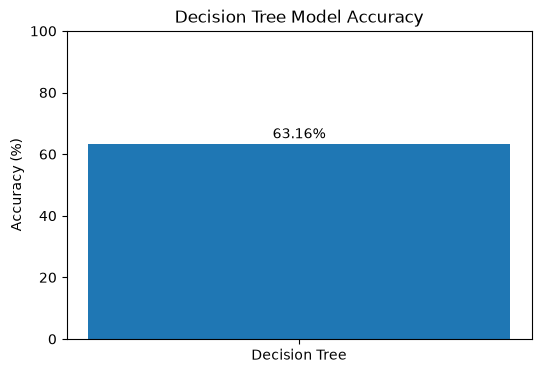

In [12]:
import matplotlib.pyplot as plt

accuracy_percent = accuracy * 100

plt.figure(figsize=(6, 4))
plt.bar(["Decision Tree"], [accuracy_percent])

plt.title("Decision Tree Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.text(
    0,
    accuracy_percent + 2,
    f"{accuracy_percent:.2f}%",
    ha="center"
)

plt.show()

In [17]:
import joblib

joblib.dump(model, "decision_tree_model.pkl")
joblib.dump(encoder, "input_encoder.pkl")
joblib.dump(label_encoder, "target_encoder.pkl")

print("Model and encoders saved successfully!")

Model and encoders saved successfully!


In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=4,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "SVM": SVC()
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy (%)
0,Decision Tree,63.16
1,Random Forest,57.89
2,SVM,57.89


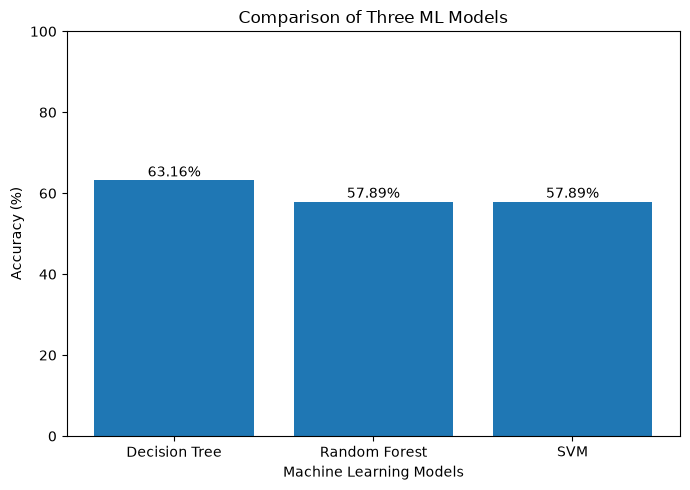

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(results_df["Model"], results_df["Accuracy (%)"])

plt.title("Comparison of Three ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(results_df["Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison = []

for name, clf in models.items():
    predictions = clf.predict(X_test)

    comparison.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, predictions) * 100, 2),
        "Precision (Weighted)": round(precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ), 2),
        "Recall (Weighted)": round(recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ), 2),
        "F1-Score (Weighted)": round(f1_score(
            y_test, predictions, average="weighted", zero_division=0
        ), 2)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,Model,Accuracy (%),Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Decision Tree,63.16,0.57,0.63,0.59
1,Random Forest,57.89,0.56,0.58,0.53
2,SVM,57.89,0.40,0.58,0.47
